# Week 3: Clustering

**Emma Deyell, Saba Sitter**

In this workshop, we will work through a set of problems on  clustering, another cannonical form of unsupervised learning. Clustering is an important tool that is used to discover homogeneous groups of data points within a heterogeneous population. It can be the main goal in some problems, while in others it may be used in EDA to understand the main types of behaviour in the data or in feature engineering.   

We will start by generating some artificial data, and then we will utilise clustering algorithms described in lectures and explore the impact of feature engineering on the solution. We will then attempt to find clusters in a gene expression dataset. 

As usual, the worksheets can be completed in teams of  up to 3 students. Instructions for submitting your workshops can be found at the end of worksheet. As a reminder, **you must submit a pdf of your notebook on Learn by 16:00 PM on the Friday** of the week the workshop was given. 

As you work through the problems it will help to refer to your lecture notes. The exercises here are designed to reinforce the topics covered this week. Please discuss with the tutors if you get stuck, even early on! 

## Outline

1. [Problem Definition and Setup: Simulated Example](#setup1)
2. [K-means: Simulated Example](#kmeans1)
3. [Hierarchical Clustering: Simulated Example](#hc)
4. [Gene Expression Data](#genedata)
5. [Hierarchical Clustering: Gene Expression Data](#hc_genedata)
6. [K-means Clustering: Gene Expression Data](#kmeans_genedata)

# Problem Definition and Setup: Simulated Example <a id='setup1'></a>

## Packages

First, load the packages required for the worksheet. 

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd 
import seaborn as sns 

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster import hierarchy

## Data: Simulated Example

We will begin with a simple simulated example in which there are truly three clusters. We assume that there are $D=2$ features and within each cluster, the data points are generated from a spherical normal distribution $N(\mathbf{m}_k, \sigma^2_k \mathbf{I})$ for clusters $k=1,2,3$, where both the mean $\mathbf{m}_k$ and variance $\sigma^2_k$ are different across clusters. Specifically, we assume that: 

* Cluster 1: contains $|C_1|=500$ points with mean vector $\mathbf{m}_1 = \begin{pmatrix} 0 \\ 4 \end{pmatrix}$ with standard deviation $\sigma_1 = 2$.
* Cluster 2: contains $|C_2|=250$ points with mean vector $\mathbf{m}_2 = \begin{pmatrix} 0 \\ -4 \end{pmatrix}$ with standard deviation $\sigma_2 = 1$.
* Cluster 3: contains $|C_3|=100$ points with mean vector $\mathbf{m}_3 = \begin{pmatrix} -4 \\ 0 \end{pmatrix}$ with standard deviation $\sigma_3 = 0.5$.

Run the following code to generate the dataset described above.

In [5]:
# Number of features
D = 2

# Cluster sizes
N_1 = 500
N_2 = 250
N_3 = 100

# Cluster means
m_1 = np.array([0., 4.])
m_2 = np.array([0., -4.])
m_3 = np.array([-4., 0.])

# Cluster standard deviations
sd_1 = 2.
sd_2 = 1.
sd_3 = 0.5

# Generate the data
rnd = np.random.RandomState(5)
X_1 = rnd.normal(loc = m_1, scale = sd_1, size = (N_1,D))
X_2 = rnd.normal(loc = m_2, scale = sd_2, size = (N_2,D))
X_3 = rnd.normal(loc = m_3, scale = sd_3, size = (N_3,D))
X = np.vstack((X_1, X_2, X_3))

# Save true cluster labels
cl = np.hstack((np.repeat(1,N_1),np.repeat(2,N_2),np.repeat(3,N_3)))

array([[ 8.82454974e-01,  3.33825970e+00],
       [ 4.86154237e+00,  3.49581574e+00],
       [ 2.19219683e-01,  7.16496223e+00],
       [-1.81846481e+00,  2.81672668e+00],
       [ 3.75206452e-01,  3.34026008e+00],
       [-2.38552922e+00,  3.59024698e+00],
       [-7.17657894e-01,  5.20694321e+00],
       [-3.32957706e+00,  2.59964192e+00],
       [ 2.30278202e+00,  7.71466201e+00],
       [-3.02235912e+00,  5.28969502e+00],
       [-1.96121577e+00,  2.28629369e+00],
       [-1.74375837e+00,  3.15498414e+00],
       [ 1.99287965e+00,  5.42484254e+00],
       [ 1.18288486e-01,  3.27337824e+00],
       [ 6.57768587e-03,  3.78813912e+00],
       [ 1.58610664e+00,  2.73685674e+00],
       [-1.23898170e-02,  3.79786478e+00],
       [-1.04616302e-01,  4.49843532e+00],
       [ 3.95320182e-01,  6.66969715e+00],
       [-1.73751213e-01,  7.12306459e+00],
       [-6.11706042e-01,  3.04453717e+00],
       [ 2.01476378e-01,  4.71087694e+00],
       [ 5.39224813e-01,  6.58392677e+00],
       [ 2.

### 🚩 Exercise 1 (CORE)

Visualise the data and color by the true cluster labels.

In [11]:
# Code for answer here!
plt.scatter(X[:,0], X[:,1], )

array([[ 0.88245497,  3.3382597 ],
       [ 4.86154237,  3.49581574],
       [ 0.21921968,  7.16496223],
       ...,
       [-4.64864902, -0.40643262],
       [-4.64829067,  0.83146655],
       [-4.51299691,  0.49870296]], shape=(850, 2))

# K-means Clustering: Simulated Example <a id='kmeans1'></a>

To perform K-means clustering, we will use `KMeans()` in `sklearn.cluster`. The documentation is available [here](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), and for an overview of clustering methods available in `sklearn`, see [link](https://scikit-learn.org/stable/modules/clustering.html). There are different inputs we can specify when calling `KMeans()` such as:

- `n_clusters`: the number of clusters. 
- `init`: which specifies the intialisation of the centroids, e.g. can be set to `k-means++` for K-means++ initialisation or `random` for random initialisation.
- `n_init`: which specifies the number of times the algorithm is run with different random initialisations
- `random_state`: this can bet set to a fixed number to make results reproducible.

We can then use the `.fit()` method of `KMeans` to run the K-means algorithm on our data.

After fitting, some of the relevant attributes of interest include:

- `labels_`: cluster assignments of the data points.
- `cluster_centers_`: mean corresponding to each cluster, stored in a matrix of size: number of clusters $K$ times number features $D$.
- `inertia_`: the total within-cluster variation.

We can also call the methods `.transform()` and `.predict()` on our fitted `KMeans()` objects. The former transforms/encodes an $N \times D$ feature matrix into an $N \times C$ matrix, where the new features reprent the distance to cluster $c$, for $c=1,\ldots, C$. The latter predicts the cluster labels of each sample in  an $N \times D$ feature matrix (i.e. returns the index of the closest cluster).

### 🚩 Exercise 2 (CORE)

Let's start by exploring how the clustering changes across the K-means iterations. Set the parameters in `KMeans()` to the following values: 

- number of clusters to 3
- initialisation to random
- number of times the algorithm is run to 1
- fix the random seed to 0


a) Now, fit the K-means algorithms with different values of the maximum number of iterations fixed to 1,2,3, and the default value of 300. 

b) Plot the data points colored by cluster for the four different cases and mark the cluster centers to observe how the clustering solution changes across iterations. 

c) How many iterations are needed for the convergence?
<br><br>
<details><summary><b><u>Hint</b></u></summary>
    
- To find the number of iterations, check the attributes of [`KMeans`](https://scikit-learn.org/1.5/modules/generated/sklearn.cluster.KMeans.html)
    
</details>

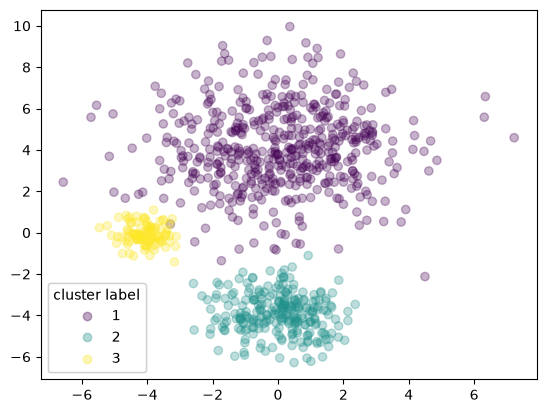

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[ 0.51, 4

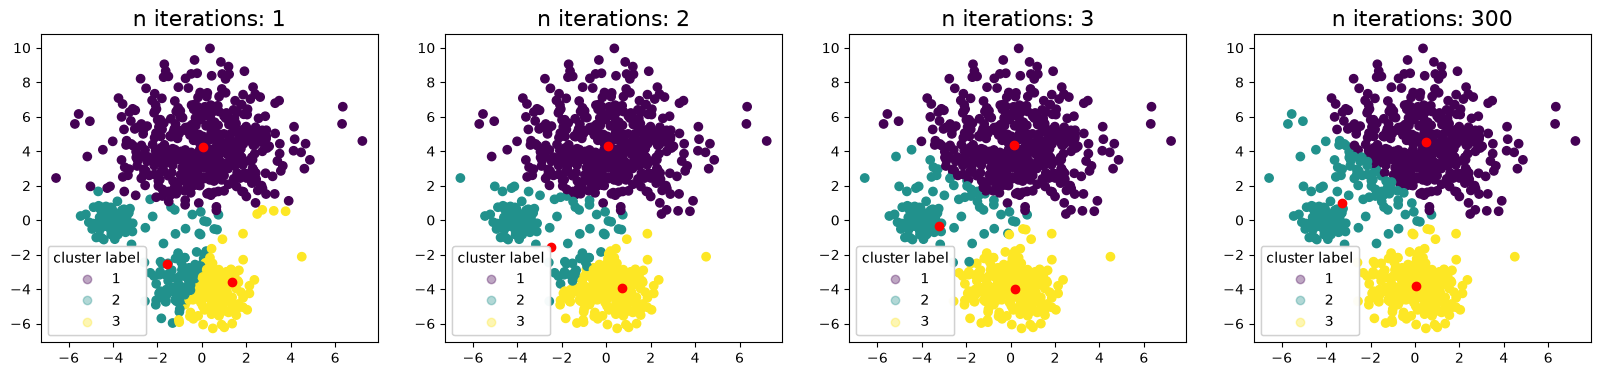

In [70]:
# Part a: Code for answer here!
fig, ax = plt.subplots()
scatter = ax.scatter(X[:,0], X[:,1],alpha=0.3, c = cl)
legend = ax.legend(*scatter.legend_elements(),
loc="lower left", title="cluster label")
ax.add_artist(legend)


plt.show()

fig,ax = plt.subplots(1,4, figsize = (20,4))
n_iterations = [1,2,3,300]
for i in range(4):
    data = list(X)
    kmeans = KMeans(n_clusters = 3, init = 'random', n_init = 1, max_iter = n_iterations[i], random_state = 0)
    kmeans.fit(data)
    ax[i].scatter(X[:,0], X[:,1], c=kmeans.labels_, label = kmeans.labels_)
    ax[i].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', label='centers')
    ax[i].set_title(f'n iterations: {n_iterations[i]}', fontsize=16)
    legend = ax[i].legend(*scatter.legend_elements(), loc="lower left", title="cluster label")
    ax[i].add_artist(legend)

kmeans

In [34]:
# Part b: Code for answer here!
kmeans.cluster_centers_[0]

array([0.51222292, 4.5140075 ])

In [ ]:
# Part c: Code for answer here!

### 🚩 Exercise 3 (CORE)

Next, compare the random intialisation used above with the intialisation used in K-means++ (in this case fix the number of different initializations to 10). Plot both clustering solutions. Which requires fewer iterations? and which provides a lower within-cluster variation?

In [ ]:
# Code for answer here!

_Type answer here_

### 🚩 Exercise 4 (CORE)

In the following two code cells, we compare the clustering solution using a different number of initialisations equal to 1, 2, 5, 10, and 20 for kmeans++ initialisation (first cell) and random initialisation (second cell). 

Based on the results, comment on the preferred initialisation strategy and how many intialisations are needed? Try changing the random state; how does that change your conclusions?

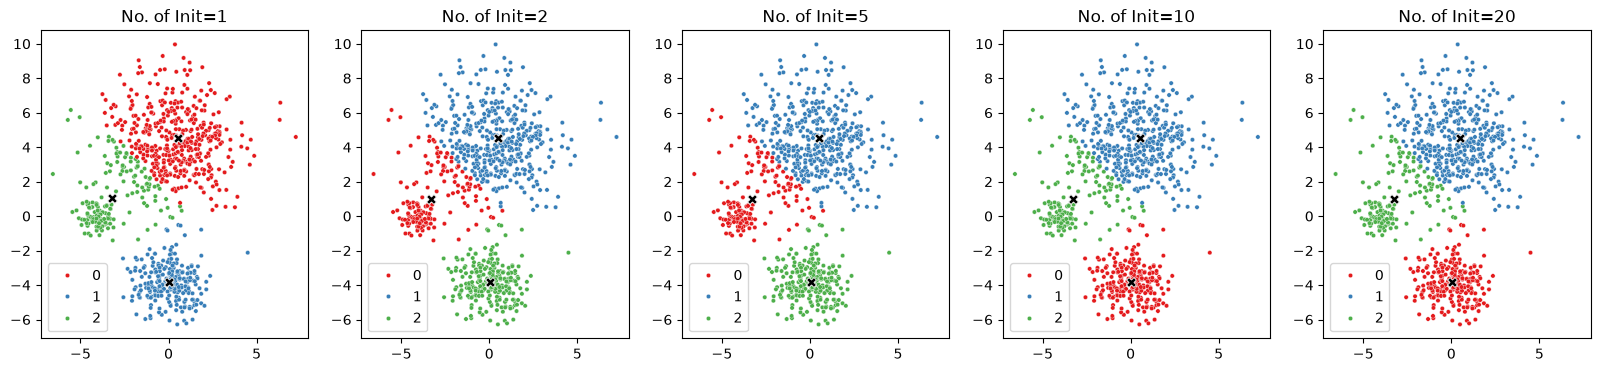

WCV=3833.368 for no. of init =1
WCV=3833.3076 for no. of init =2
WCV=3833.3076 for no. of init =5
WCV=3833.2826 for no. of init =10
WCV=3833.2826 for no. of init =20


In [38]:
# Kmeans++ initialisation
# Plotting the clustering solution with different number of initialisations 
n_init = np.array([1,2,5,10,20])

rs = 0

fig, ax = plt.subplots(1,n_init.shape[0],figsize=(20,4))
for n in range(n_init.shape[0]):
    kmeans_n = KMeans(n_clusters = 3, n_init = n_init[n], random_state=rs).fit(X)
    sns.scatterplot(x=X[:,0], y=X[:,1], hue=kmeans_n.labels_, palette='Set1', s=10, ax=ax[n])
    sns.scatterplot(x=kmeans_n.cluster_centers_[:,0], y=kmeans_n.cluster_centers_[:,1], 
                    c='black', s=50, marker='X', ax=ax[n])
    ax[n].set_title("No. of Init="+str(n_init[n]))
plt.show()

# Print the within cluster variation
for n in range(n_init.shape[0]):
    kmeans_n = KMeans(n_clusters = 3, n_init = n_init[n], random_state=rs).fit(X)
    print("WCV="+str(round(kmeans_n.inertia_,4))+' for no. of init ='+ str(n_init[n]))

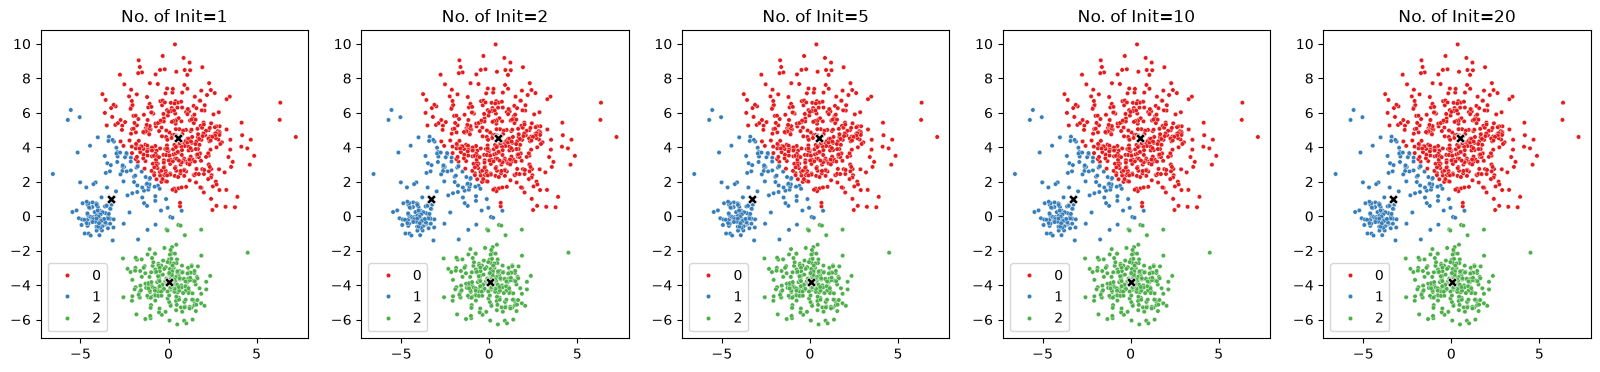

WCV=3833.3076 for no. of init =1
WCV=3833.3076 for no. of init =2
WCV=3833.3076 for no. of init =5
WCV=3833.3076 for no. of init =10
WCV=3833.3076 for no. of init =20


In [39]:
# Random initialisation
# Plotting the clustering solution with different number of initialisations 
n_init = np.array([1,2,5,10,20])

rs = 0

fig, ax = plt.subplots(1,n_init.shape[0],figsize=(20,4))
for n in range(n_init.shape[0]):
    kmeans_n = KMeans(n_clusters = 3, init = 'random', n_init = n_init[n], random_state=rs).fit(X)
    sns.scatterplot(x=X[:,0], y=X[:,1], hue=kmeans_n.labels_, palette='Set1', s=10, ax=ax[n])
    sns.scatterplot(x=kmeans_n.cluster_centers_[:,0], y=kmeans_n.cluster_centers_[:,1], 
                    c='black', s=50, marker='X', ax=ax[n])
    ax[n].set_title("No. of Init="+str(n_init[n]))
plt.show()

# Print the within cluster variation
for n in range(n_init.shape[0]):
    kmeans_n = KMeans(n_clusters = 3, init = 'random',n_init = n_init[n], random_state=rs).fit(X)
    print("WCV="+str(round(kmeans_n.inertia_,4))+' for no. of init ='+ str(n_init[n]))

_Type your answer here_

### 🚩 Exercise 5 (CORE)

Since we simulated the data, we know the true number of clusters. However, in practice this number is rarely known. Find the K-means solution with different choices of $K$ and plot the within-cluster variation as a function of $K$. What value(s) of $K$ seem appropriate based on this plot?

In [ ]:

# Code for answer here!

_Type your answer here_

### 🚩 Exercise 6 (CORE)

Now let's use the silhouette analysis to choose the number of clusters. In the following code cells, we use [`silhouette_samples`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_samples.html) to compute the silhouette coefficient for each data point, and [`silhouette_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) which computes the mean of the silhouette coefficients across all data points.

a) How many clusters would you choose based only on maximising the silhouette score?

b) Considering also the violin plots, which visualise the distribution of the silhouette coefficient across data points within each cluster, would you still choose the same number of clusters or pick a different number? Why?

In [ ]:
from sklearn.metrics import silhouette_samples, silhouette_score

# Define the range of possible number of clusters
K = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10])

# First plot the silhouette coeffcient for different choices of K
silhouette_coeffs = np.zeros(K.shape)
for i in range(K.shape[0]):
    #Define kmeans object, fit, and predict labels
    kmeans_K = KMeans(n_clusters = K[i], n_init = 20, random_state=0).fit(X)
    labs = kmeans_K.predict(X)
    # Compute silhouette coefficient
    silhouette_coeffs[i] = silhouette_score(X, labs)

# Plot the silhouette coefficients
fig, ax = plt.subplots(1,1,figsize=(5,4))
sns.lineplot(x=K, y=silhouette_coeffs, linestyle='dashed', ax=ax)
sns.scatterplot(x=K, y=silhouette_coeffs, ax=ax)
plt.xlabel('K')
plt.ylabel('Silhouette Coefficient')
plt.show()

In [ ]:
# Plot the silhouette samples for different choices of K

max_i = 4
fig, ax = plt.subplots(2, 5, figsize=(25, 10))  
for i in range(max_i+1):
    kmeans_K = KMeans(n_clusters = K[i], n_init = 20, random_state=0).fit(X)
    labs = kmeans_K.predict(X)
    silhouette_samps = silhouette_samples(X, labs)

    # Create a violin plot of the silhouette samples
    sns.violinplot(y=silhouette_samps, hue=labs, ax=ax[0,i], palette='Set1')
    ax[0,i].axhline(silhouette_samps.mean(), ls='--',c="gray")
    ax[0,i].set_title(f'Silhouette Samples for K={K[i]}')
    ax[0,i].set_ylabel('Silhouette Coefficient')
    ax[0,i].set_xlabel('')
    ax[0,i].set_ylim([-0.2, 1])

    # Plot the clustering solution
    sns.scatterplot(x=X[:,0], y=X[:,1], hue=labs, ax=ax[1,i], palette='Set1')
    sns.scatterplot(x=kmeans_K.cluster_centers_[:,0], y=kmeans_K.cluster_centers_[:,1], 
                    c='black', s=50, marker='X', ax=ax[1,i])
    ax[1,i].set_title(f'Clustering Solution for K={K[i]}')
    ax[1,i].set_ylabel('X2')
    ax[1,i].set_xlabel('X1')

_Type your answer here_

### 🚩 Exercise 7 (CORE)

Now standardise the data and re-run the K-means algorithm. Qualitatively, how has standardising the data impacted performance? Can you argue why you observe what you see?

In [ ]:
# Code for answer here!

_Type your answer here_

# Hierarchical Clustering: Simulated Example <a id='hc'></a>

To perform hierarchical clustering, we will use the [`linkage()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html) function from `scipy.cluster.hierarchy`. The inputs to specify include

-  the data. 
- `metric`: specifies the dissimarlity between data points. Defaults to the Euclidean distance.
- `method`: specifies the type of linkage, e.g. complete, single, or average.

Then, we can use [`dendrogram()`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html) from `scipy.cluster.hierarchy` to plot the dendrogram.

Note that you can also use [`AgglomerativeClustering`](https://scikit-learn.org/1.5/modules/generated/sklearn.cluster.AgglomerativeClustering.html) from `sklearn.cluster`, which similarly has options for `metric` to specify the distance and `linkage` to specify the type of linkage. However, `sklearn` does not have its own functions for plotting the dendogram and use must use the tools from `scipy.cluster.hierarchy`.  

### 🚩 Exercise 8 (CORE)

a) For the following code cell, what is the dissimarlity metric and what is the linkage used in hierarchical clustering?

In [87]:
hc_comp = hierarchy.linkage(X, method='complete')

From the linkage documentation, if the 'metric' input isn't specified, the dissimilarity metric defaults to the Euclidean distance. The linkage used above is 'complete' which is given by $d(u,v)=\max(dist(u[i], v[j]))$ for all points i in cluster u and j in cluster v.

b)  Plot the dendogram by running the code below. Try changing the 'color_threshold' to a number (e.g. 11) to color the branches of the tree below the threshold with different colors. How many clusters are identified if the tree is cut at that threshold?

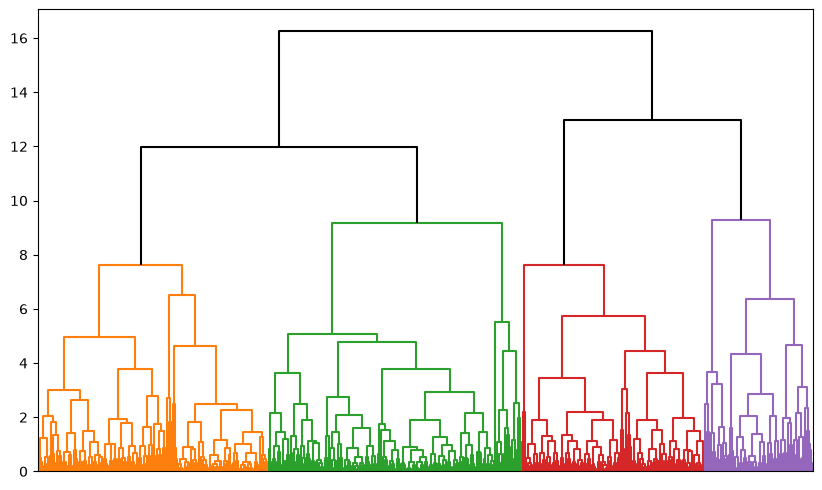

In [47]:
# Plot the dendrogram
fig, ax = plt.subplots(1, 1, figsize=(10,6))
hierarchy.dendrogram(hc_comp, ax=ax, no_labels=True,
                     color_threshold=11, above_threshold_color='black')
plt.show()

There are 4 different colours in the dendogram at color_threshold = 11 so we can identify 4 clusters.

c) Now, use the function `cut_tree()` from `scipy.cluster.hierarchy` to determine the cluster labels associated with a given cut of the dendrogram. You can either specify the number of clusters via `n_clusters` or the height/threshold at which to cut via `height`. Plot the data coloured by the cluster labels.

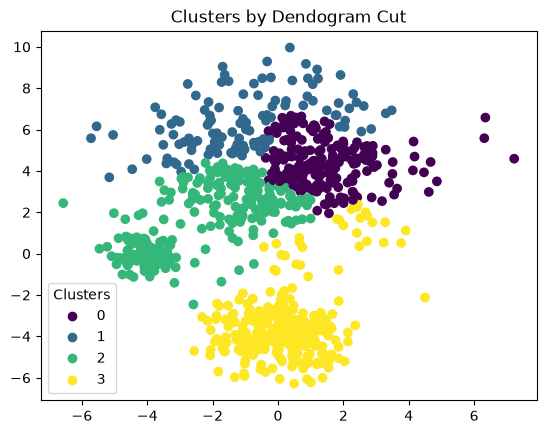

In [86]:
cluster_labels = hierarchy.cut_tree(hc_comp, n_clusters = 4).flatten()

scatter = plt.scatter(X[:, 0], X[:, 1], c=cluster_labels)
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Clusters")
plt.title('Clusters by Dendogram Cut')
plt.show()

### 🚩 Exercise 9 (CORE)

Now try changing the linkage to single and average. Does this affect on the results?

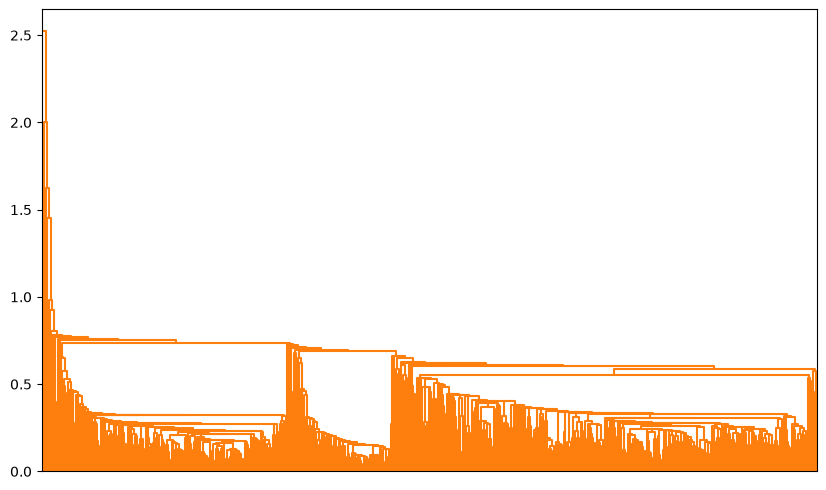

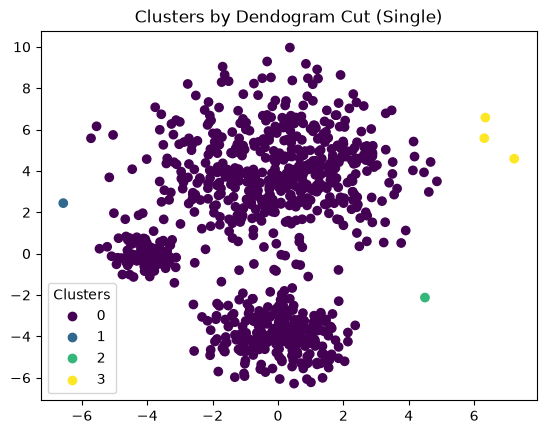

In [93]:
# Code for answer here
# First: change to single linkage, plot the dendrogram, and visualize the clustering solution by cutting the tree
hc_comp_single = hierarchy.linkage(X, method='single')

fig, ax = plt.subplots(1, 1, figsize=(10,6))
hierarchy.dendrogram(hc_comp_single, ax=ax, no_labels=True,
                     color_threshold= 11, above_threshold_color='black')
plt.show()

cluster_labels_single = hierarchy.cut_tree(hc_comp_single, n_clusters = 4).flatten()

scatter = plt.scatter(X[:, 0], X[:, 1], c=cluster_labels_single)
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Clusters")
plt.title('Clusters by Dendogram Cut (Single)')
plt.show()

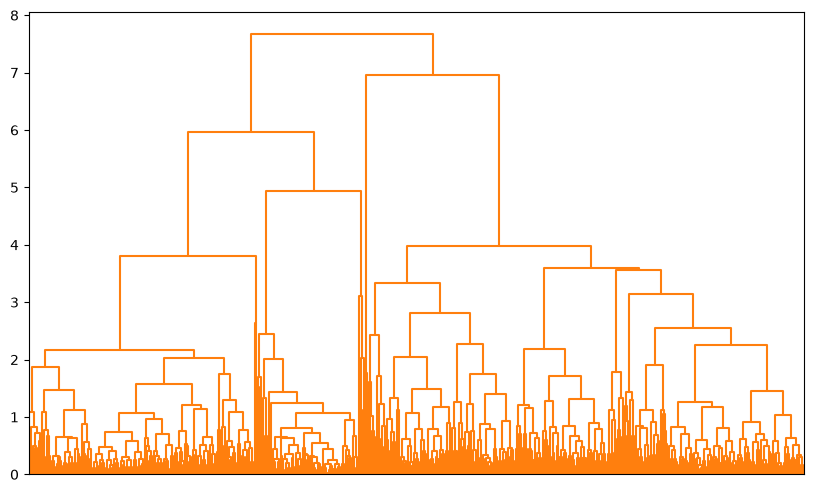

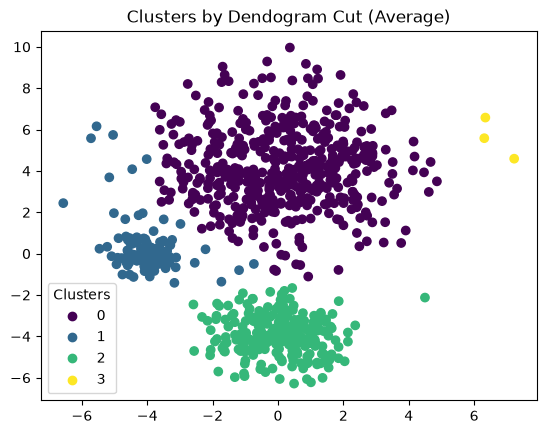

In [92]:
# Code for answer here
# Next: change to average linkage, plot the dendrogram, and visualize the clustering solution by cutting the tree
hc_comp_average = hierarchy.linkage(X, method='average')

fig, ax = plt.subplots(1, 1, figsize=(10,6))
hierarchy.dendrogram(hc_comp_average, ax=ax, no_labels=True,
                     color_threshold= 11, above_threshold_color='black')
plt.show()

cluster_labels_average = hierarchy.cut_tree(hc_comp_average, n_clusters = 4).flatten()

scatter = plt.scatter(X[:, 0], X[:, 1], c=cluster_labels_average)
handles, labels = scatter.legend_elements()
plt.legend(handles, labels, title="Clusters")
plt.title('Clusters by Dendogram Cut (Average)')
plt.show()

_Type answer here_

# Gene Expression Data <a id='genedata'></a>

Now, we will consider a more complex real dataset with a larger feature space. 

The dataset is the **NCI cancer microarray dataset** discussed in both *Introduction to Statistical Learning* and  *Elements of Statistical Learning*. The dataset consists of $D=6830$ gene expression measurements for each of $N=64$ cancer cell lines. The aim is to determine whether there are groups among the cell lines with similar gene expression patterns. This is an example of a high-dimensional dataset with $D$ much larger than $N$, which makes visualisation difficult. The $N=64$ cancer cell lines have been obtained from samples of cancerous tissues, corresponding to 14 different types of cancer. However, our focus remains unsupervised learning and we will use the cancer labels only to plot. 

We first need to read in the dataset.

In [94]:
#Fetch the data and cancer labels
url_data = 'https://web.stanford.edu/~hastie/ElemStatLearn/datasets/nci.data.csv'
url_labels = 'https://web.stanford.edu/~hastie/ElemStatLearn/datasets/nci.label.txt'

X = pd.read_csv(url_data)
y = pd.read_csv(url_labels, header=None)

# clean data by dropping identifier column and transpose so that features are columns
X = X.drop(labels='Unnamed: 0', axis=1).T

In [95]:
X.shape

(64, 6830)

In [96]:
y.shape

(64, 1)

Let's visualise the data with a heatmap.

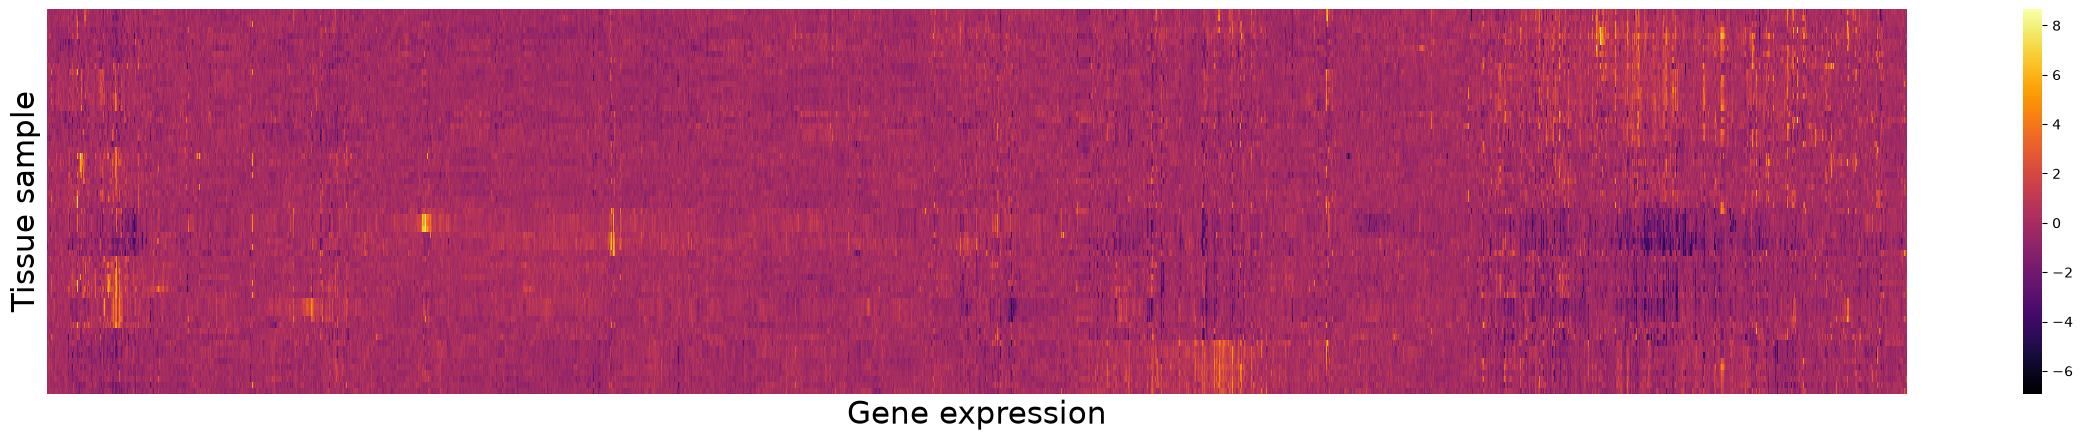

In [97]:
# Heatmap of the gene expression data
fig, ax = plt.subplots(1,1,figsize=(30,5))
sns.heatmap(X, cmap='inferno', ax=ax)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("Gene expression", fontsize=22)
ax.set_ylabel("Tissue sample", fontsize=22)
plt.show()

We now convert our pandas dataframe into a numpy array and create integer labels for cancer type (for plotting purposes)

If you print the unique labels, you will notice there are lots of inconsistencies with white space etc. Run the following code to clean the labels.

In [98]:
# Print the unique labels and counts
y.value_counts()

0                         
RENAL                         4
OVARIAN                       4
NSCLC                         3
COLON                         3
MELANOMA                      3
CNS                           2
CNS                           2
BREAST                        2
NSCLC                         2
RENAL                         2
BREAST                        2
MELANOMA                      2
PROSTATE                      2
NSCLC                         2
LEUKEMIA                      2
COLON                         2
MELANOMA                      2
CNS                           1
RENAL                         1
BREAST                        1
NSCLC                         1
RENAL                         1
RENAL                         1
NSCLC                         1
UNKNOWN                       1
OVARIAN                       1
OVARIAN                       1
LEUKEMIA                      1
K562B-repro                   1
K562A-repro                   1
LEUKEMIA     

In [99]:
# Clean the labels by stripping the white space
y_clean = np.asarray(y).flatten()
for j in range(y_clean.size):
    y_clean[j] = y_clean[j].strip()

cancer_types = list(np.unique(y_clean))
cancer_groups = np.array([cancer_types.index(lab) for lab in y_clean])

In [100]:
pd.Series(y_clean).value_counts()

RENAL          9
NSCLC          9
MELANOMA       8
BREAST         7
COLON          7
OVARIAN        6
LEUKEMIA       6
CNS            5
PROSTATE       2
UNKNOWN        1
K562B-repro    1
K562A-repro    1
MCF7A-repro    1
MCF7D-repro    1
Name: count, dtype: int64

In [101]:
X_array = np.asarray(X)

### 🚩 Exercise 10 (EXTRA)

Perform a PCA of $\mathbf X$ to visualise the data. Plot the first few principal component scores and colour by cancer type. Do cell lines within the same cancer types seems to have similar scores? Make a scree plot of the proportion of variance explained. How many components does this suggest?

In [ ]:
from sklearn.decomposition import PCA

# Code for answer here!

_Type answer here_

# Hierarchical Clustering: Gene Expression Data <a id='hc_genedata'></a>

Now, let's perform hierarchical clustering on the gene expression data. 

### 🚩 Exercise 11 (CORE)

a) Plot the dendrogram with complete, single, and average linkage. Does the choice of linkage affect the results? Which linkage would you choose?

In [ ]:
# Code for your answer here!
# Fit hierarchical clustering with different types of linkage


# Plot the dendogram


_Type your answer here_

b) Select a linkage and a number of clusters (by examining the dendrogram and jumps in the heights of the clusters merged). Plot the dendogram and color the branches to identify the clusters. Use the option `labels = np.asarray(y_clean), leaf_font_size=10` in `hierarchy.dendrogram` to add the cancer types as labels for each data point. Do you observe any patterns between the clusters and cancer types? You may also want to use `pd.crosstab` to compute a cross-tabulation to compare the clusters and cancer types.

In [118]:
# Code for your answer here!
X

,0,1,2,3,4,5,6,7,8,9,...,6820,6821,6822,6823,6824,6825,6826,6827,6828,6829
s1,0.300000,1.180000,0.550000,1.140000,-0.265000,-7.000000e-02,0.350000,-0.315000,-0.450000,-0.654980,...,-0.990020,0.000000,0.030000,-0.175000,0.629981,-0.030000,0.000000,0.280000,-0.340000,-1.930000
s2,0.679961,1.289961,0.169961,0.379961,0.464961,5.799610e-01,0.699961,0.724961,-0.040039,-0.285019,...,-0.270058,-0.300039,-0.250039,-0.535039,0.109941,-0.860039,-1.250049,-0.770039,-0.390039,-2.000039
s3,0.940000,-0.040000,-0.170000,-0.040000,-0.605000,0.000000e+00,0.090000,0.645000,0.430000,0.475019,...,0.319981,0.120000,-0.740000,-0.595000,-0.270020,-0.150000,0.000000,-0.120000,-0.410000,0.000000
s4,0.280000,-0.310000,0.680000,-0.810000,0.625000,-1.387779e-17,0.170000,0.245000,0.020000,0.095019,...,-1.240020,-0.110000,-0.160000,0.095000,-0.350019,-0.300000,-1.150010,1.090000,-0.260000,-1.100000
s5,0.485000,-0.465000,0.395000,0.905000,0.200000,-5.000000e-03,0.085000,0.110000,0.235000,1.490019,...,0.554980,-0.775000,-0.515000,-0.320000,0.634980,0.605000,0.000000,0.745000,0.425000,0.145000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
s60,-0.030000,-0.480000,0.070000,-0.700000,-0.195000,4.100000e-01,-0.240000,0.105000,-0.410000,0.875019,...,-0.400019,0.150000,-0.430000,0.145000,-0.090020,-0.020000,-1.390010,-1.150000,0.290000,1.190000
s61,-0.270000,0.630000,-0.100000,1.100000,1.045000,8.000000e-02,-0.090000,-0.675000,-0.310000,0.275019,...,-0.560020,0.200000,0.290000,-0.035000,0.279981,-0.160000,-0.020010,-0.640000,-0.370000,-0.430000
s62,0.210000,-0.620000,-0.150000,-1.330000,0.045000,-4.000000e-01,-0.390000,-0.675000,-0.360000,0.945020,...,-0.160020,-0.120000,0.850000,-0.125000,0.779980,0.390000,0.000000,0.160000,2.030000,3.940000
s63,-0.050000,0.140000,-0.090000,-1.260000,0.045000,-2.710505e-20,0.420000,-0.305000,0.310000,0.065019,...,0.889980,-0.420000,-0.460000,-0.855000,-0.160020,-0.350000,-0.360010,-0.490000,0.010000,-1.720000


_Type your answer here_

# K-means Clustering: Gene Expression Data <a id='kmeans_genedata'></a>

Now, let's perform k-means clustering on the gene expression data.

### 🚩 Exercise 12 (CORE)

Perform K-means clustering with the same number of clusters that you selected for hierarchical clustering. Are the results similar?

In [127]:
# Code for your answer here!
kmeans_4 = KMeans(n_clusters = 4, init = 'random', n_init = 1, random_state = 0)
kmeans_4.fit(X)
kmeans_4

kmeans_4

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 6830)","[[-0.05

_Type your answer here_

### 🚩 Exercise 13 (EXTRA)

Plot the two clustering solutions along with a plot of the data colored by the cancer types in the space spanned by the first two principal components.

In [ ]:
# Code for your answer here!

# Competing the Worksheet

At this point you have hopefully been able to complete all the CORE exercises and attempted the EXTRA ones. Now 
is a good time to check the reproducibility of this document by restarting the notebook's
kernel and rerunning all cells in order.

Before generating the PDF, please **change 'Student 1' and 'Student 2' at the top of the notebook to include your name(s)**.

Once that is done and you are happy with everything, you can then run the following cell 
to generate your PDF.

In [ ]:
!jupyter nbconvert --to pdf mlp_week03.ipynb 